# How Good is This Model?

Here's a [question from the Reddit statistics forum](https://www.reddit.com/r/AskStatistics/comments/1havonz/multiple_linear_regression_low_r2_value_but/).

>  Multiple Linear Regression: low R^2 value, but highly significant p-values (<0.01)
>
> I am currently running a statistical analysis using Multiple Linear Regression (MLR), and I encountered a problem in that the regression produces a low R^2 value (0.21), but all 12 of my independent variables have a p-value less than 0.01.
>
> For some context, I am doing an analysis using a public database related to social services. My sample size is roughly 10000, and the goal of this analysis is to find out whether the independent variables (factors) have an impact on the dependent variable.
>
> Could you also recommend further diagnostic tests or other statistical analyses to justify the findings? Thank you!

This is a common question, and it makes sense because we think of both $R^2$ and p-values as way to quantify how good a model is.
If the model describes the data generating process well, we expect $R^2$ to be high and the p-values to be small.
When the two metrics are not consistent, it seems like there's something that needs to be explained.

But that's not right -- the two metrics quantify different things:

* If the p-values are small, that suggests that the associations between the dependent and independent variables are unlikely to be due to chance.

* If $R^2$ is large, that means that the independent variables are predictive -- that is, if we know the independent variables, we can make better guesses about the dependent variable.

So it is possible to have small p-values and small $R^2$ at the same time.
In fact, it is quite common, especially when sample sizes are large.

[Click here to run this notebook on Colab](https://colab.research.google.com/github/AllenDowney/DataQnA/blob/main/nb/XXX.ipynb).

I'll download a utilities module with some of my frequently-used functions, and then import the usual libraries.

In [1]:
from os.path import basename, exists

def download(url):
    filename = basename(url)
    if not exists(filename):
        from urllib.request import urlretrieve

        local, _ = urlretrieve(url, filename)
        print("Downloaded " + str(local))
    return filename

download('https://github.com/AllenDowney/DataQnA/raw/main/nb/utils.py')

'utils.py'

In [2]:
# install the empiricaldist library, if necessary

try:
    import empiricaldist
except ImportError:
    !pip install empiricaldist

In [3]:
import numpy as np
np.set_printoptions(legacy='1.25')
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from utils import decorate, display_summary

## Answer

In [4]:
def generate_data(n, sigma):
    inter = 10
    beta1, beta2 = 2, 3
    x1 = np.random.normal(3, 1, size=n)
    x2 = np.random.normal(3, 1, size=n)
    error = np.random.normal(0, sigma, size=n)
    y = inter + beta1 * x1 + beta2 * x2 + error
    
    return pd.DataFrame(dict(y=y, x1=x1, x2=x2))

In [5]:
np.random.seed(1)
data = generate_data(1000, 7)

In [6]:
import statsmodels.formula.api as smf

results = smf.ols('y ~ x1 + x2', data=data).fit()
display_summary(results)

,coef,std err,t,P>|t|,[0.025,0.975]
Intercept,11.5175,0.933,12.339,0.000,9.686,13.349
x1,1.6534,0.219,7.541,0.000,1.223,2.084
x2,2.7954,0.209,13.388,0.000,2.386,3.205


R-squared:,0.1944


In [7]:
def scatter(data, xvar):
    plt.scatter(data[xvar], data['y'], marker='.', alpha=0.5)
    decorate(xlabel=xvar, ylabel='y')

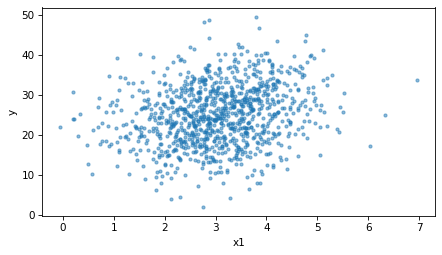

In [8]:
scatter(data, 'x1')

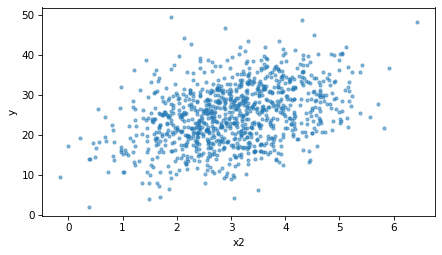

In [9]:
scatter(data, 'x2')

In [10]:
data.corr()

,y,x1,x2
y,1.000000,0.222737,0.385336
x1,0.222737,1.000000,0.021857
x2,0.385336,0.021857,1.000000


In [11]:
sigma = 7
ns = np.logspace(2, 3)
res = []

for n in ns:
    n = round(n)
    data = generate_data(n, sigma)
    results = smf.ols('y ~ x1 + x2', data=data).fit()
    res.append((results.rsquared, results.pvalues['x1'], results.pvalues['x2']))

columns = ['rsquared', 'p-value x1', 'p-value x2']
sweep_n = pd.DataFrame(res, index=ns, columns=columns)

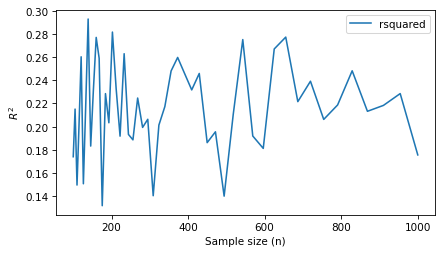

In [12]:
sweep_n['rsquared'].plot()
decorate(xlabel='Sample size (n)', ylabel='$R^2$')

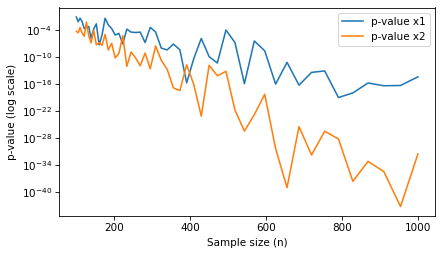

In [13]:
sweep_n['p-value x1'].plot()
sweep_n['p-value x2'].plot()
decorate(xlabel='Sample size (n)', ylabel='p-value (log scale)', yscale='log')

In [14]:
n = 50
sigmas = np.linspace(1, 7)
res = []

for sigma in sigmas:
    n = round(n)
    data = generate_data(n, sigma)
    results = smf.ols('y ~ x1 + x2', data=data).fit()
    res.append((results.rsquared, results.pvalues['x1'], results.pvalues['x2']))

columns = ['rsquared', 'p-value x1', 'p-value x2']
sweep_sigma = pd.DataFrame(res, index=sigmas, columns=columns)

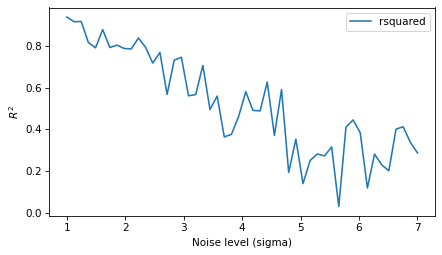

In [15]:
sweep_sigma['rsquared'].plot()
decorate(xlabel='Noise level (sigma)', ylabel='$R^2$')

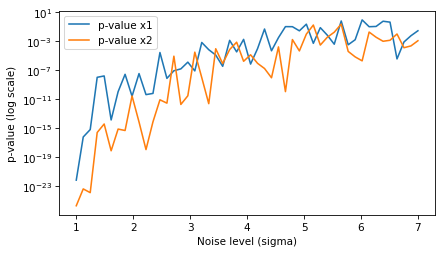

In [16]:
sweep_sigma['p-value x1'].plot()
sweep_sigma['p-value x2'].plot()
decorate(xlabel='Noise level (sigma)', ylabel='p-value (log scale)', yscale='log')

## Discussion

[*Data Q&A: Answering the real questions with Python*](https://allendowney.github.io/DataQnA/index.html)

Copyright 2024 [Allen B. Downey](https://allendowney.com)

License: [Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International](https://creativecommons.org/licenses/by-nc-sa/4.0/)